# House Prices - Advanced Regression Techniques


Predict sales prices and practice feature engineering, RFs, and gradient boosting

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

import os
try:
    from google.colab import files
    if not os.path.exists("train.csv"):
        files.upload()
except ImportError:
    pass

df = pd.read_csv("train.csv", keep_default_na=False, na_values=["NA"])
df.shape

(1460, 81)

## Pytania naprowadzające

1. Jaka jest zmienna docelowa (ang. target variable), którą chcemy przewidywać?  
2. Jakie rodzaje zmiennych są w zbiorze (liczbowe, kategoryczne, tekstowe)?  
Do zrobienia:  
3. Wyświetl podstawowe statystyki opisowe (df.describe()).  
4. Sprawdź typy danych wszystkich kolumn (df.dtypes).  
5. Sprawdź braki danych — i ustal, co oznaczają (data_description.txt).  
6. Przygotuj wykresy podobne do tych z wykładu.  


**Odpowiedzi:**  
1. Zmienną docelową jest cena sprzedaży domu, czyli kolumna SalePrice (w USD).
2. Zbiór zawiera dane liczbowe (np. LotArea, YearBuilt), dane porządkowe (np. OverallQual oceniająca dom w skali 1-10) oraz dane nominalne/kategoryczne (np. BldgType, Neighborhood).

In [4]:
# Wczytaj pełny zbiór treningowy (train.csv z Kaggle)
df = pd.read_csv('train.csv')
display(df.head())

# 3. Wyświetl podstawowe statystyki opisowe
display(df.describe())

# 4. Sprawdź typy danych wszystkich kolumn
display(df.dtypes)

# 5. Sprawdź braki danych 
braki = df.isna().sum()
print("Kolumny z największą liczbą braków (NA):")
print(braki[braki > 0].sort_values(ascending=False).head(10))

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


,0
Id,int64
MSSubClass,int64
MSZoning,object
LotFrontage,float64
LotArea,int64
...,...
MoSold,int64
YrSold,int64
SaleType,object
SaleCondition,object


Kolumny z największą liczbą braków (NA):
PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
dtype: int64


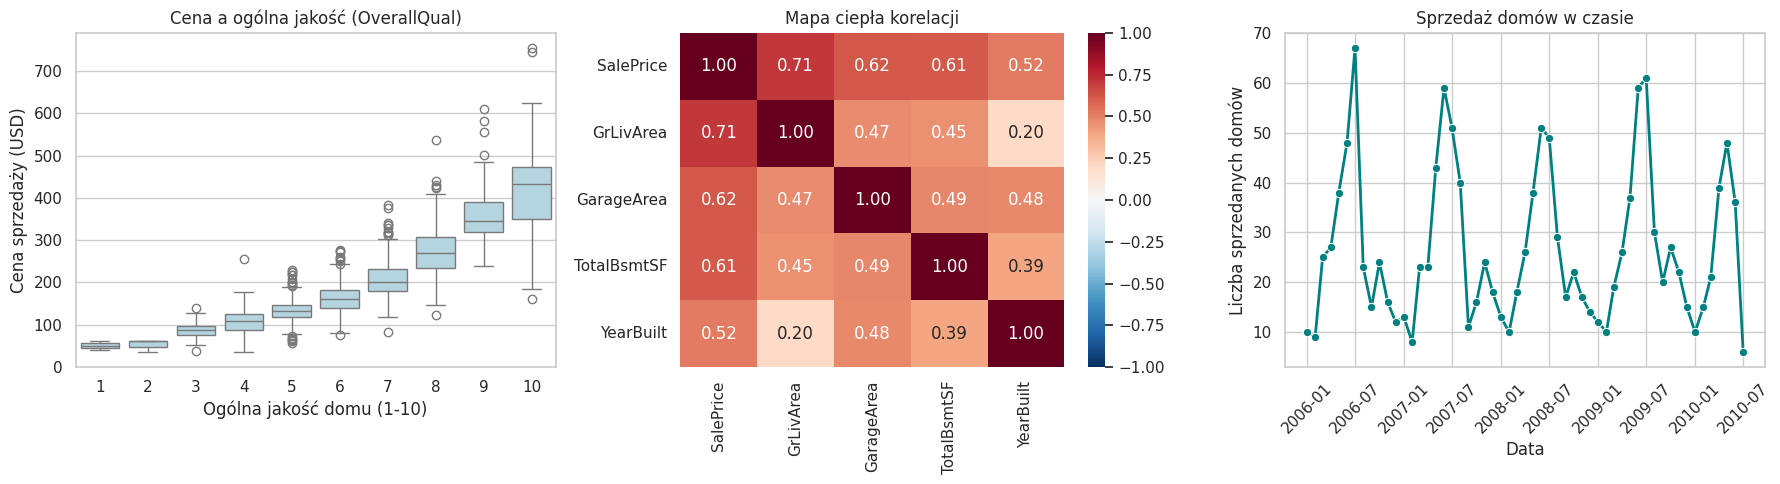

In [6]:
# 6. Przygotuj wykresy podobne do tych z wykładu.

cols = ['SalePrice', 'GrLivArea', 'GarageArea', 'TotalBsmtSF', 'YearBuilt']
corr_matrix = df[cols].corr()

# do wykresu liniowego
df['DateSold'] = pd.to_datetime(df['YrSold'].astype(str) + '-' + df['MoSold'].astype(str) + '-01')
sales_over_time = df.groupby('DateSold').size().reset_index(name='Count')

# Tworzenie figury z 3 wykresami w jednym rzędzie
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# wykres pudełkowy
sns.boxplot(x='OverallQual', y=df['SalePrice'] / 1000, data=df, color='lightblue', ax=axes[0])
axes[0].set_title('Cena a ogólna jakość (OverallQual)')
axes[0].set_xlabel('Ogólna jakość domu (1-10)')
axes[0].set_ylabel('Cena sprzedaży (USD)')

# heatmap
sns.heatmap(corr_matrix, annot=True, cmap='RdBu_r', fmt='.2f', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Mapa ciepła korelacji')

# wykres liniowy
sns.lineplot(x='DateSold', y='Count', data=sales_over_time, marker='o', color='teal', linewidth=2, ax=axes[2])
axes[2].set_title('Sprzedaż domów w czasie')
axes[2].set_xlabel('Data')
axes[2].set_ylabel('Liczba sprzedanych domów')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()



## Analiza zmiennej docelowej  

### Zadania:  
1. Histogram cen: poeksperymentuj z liczbą przedziałów (bins = 10, 30, 50). Czy rozkład jest skośny?
2. Wykres pudełkowy cen: czy widzisz wartości odstające? Co mogą oznaczać bardzo drogie domy?  
3. Policz: min, max, średnią, medianę, 𝑄1, 𝑄3, IQR.  

### Pytania 
4. Jaki jest rozkład cen?  
5. Czy są wartości odstające?  
6. Jaka jest średnia i mediana ceny?  
7. Czy ceny mają rozkład normalny? (wskazówka: czy histogram jest symetryczny?) 

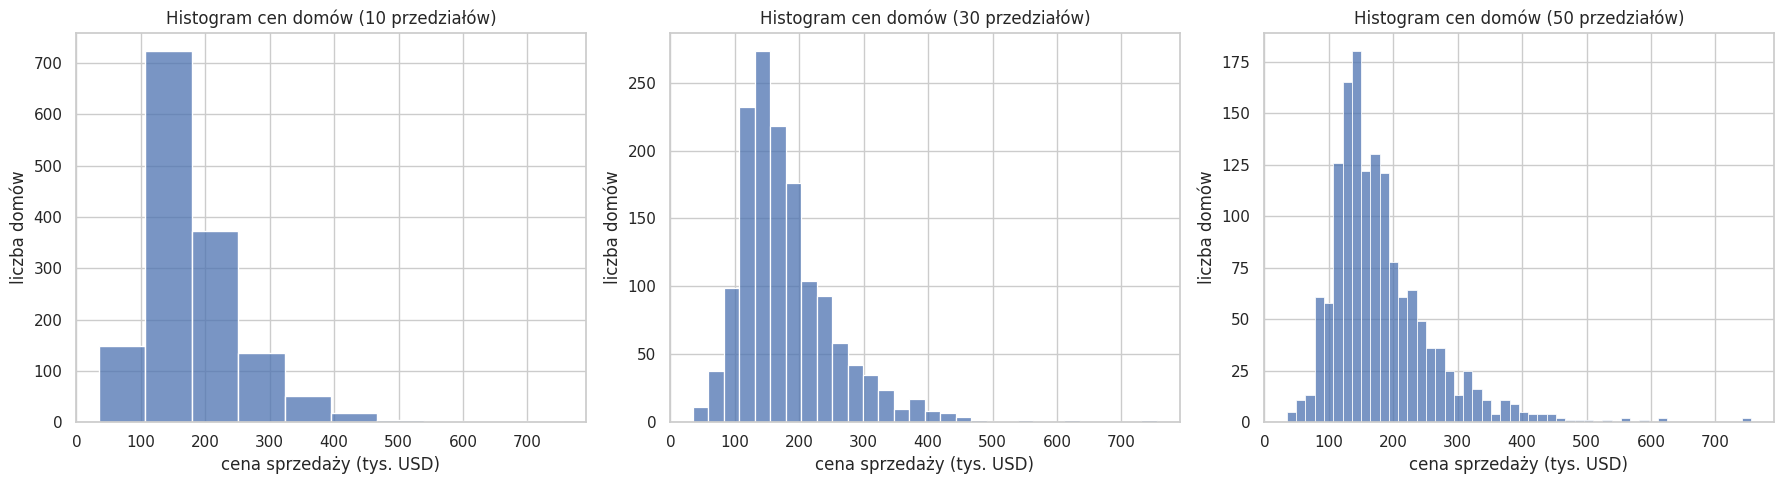

In [7]:
# 1. Histogram cen: eksperymenty z liczbą przedziałów (bins = 10, 30, 50)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.histplot(x=df['SalePrice'] / 1000, bins=10, ax=axes[0])
axes[0].set_title('Histogram cen domów (10 przedziałów)')
axes[0].set_xlabel('cena sprzedaży (tys. USD)')
axes[0].set_ylabel('liczba domów')

sns.histplot(x=df['SalePrice'] / 1000, bins=30, ax=axes[1])
axes[1].set_title('Histogram cen domów (30 przedziałów)')
axes[1].set_xlabel('cena sprzedaży (tys. USD)')
axes[1].set_ylabel('liczba domów')

sns.histplot(x=df['SalePrice'] / 1000, bins=50, ax=axes[2])
axes[2].set_title('Histogram cen domów (50 przedziałów)')
axes[2].set_xlabel('cena sprzedaży (tys. USD)')
axes[2].set_ylabel('liczba domów')

plt.tight_layout()
plt.show()

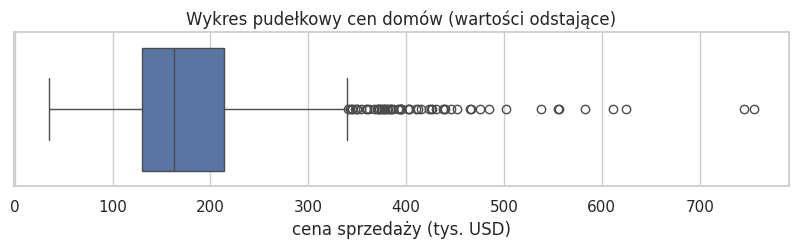

In [8]:
# 2. Wykres pudełkowy cen
plt.figure(figsize=(10, 2))
sns.boxplot(x=df['SalePrice'] / 1000).set_xlabel('cena sprzedaży (tys. USD)')
plt.title('Wykres pudełkowy cen domów (wartości odstające)')
plt.show()

In [9]:
# 3. Policz: min, max, średnią, medianę, 𝑄1, 𝑄3, IQR
Q1 = df['SalePrice'].quantile(0.25)
Q3 = df['SalePrice'].quantile(0.75)
IQR = Q3 - Q1

print("Odpowiedz pkt 3:")
print(f"Minimum: {df['SalePrice'].min()}")
print(f"Maksimum: {df['SalePrice'].max()}")
print(f"Średnia: {df['SalePrice'].mean():.2f}")
print(f"Mediana: {df['SalePrice'].median()}")
print(f"Q1 (25. percentyl): {Q1}")
print(f"Q3 (75. percentyl): {Q3}")
print(f"IQR: {IQR}")


Odpowiedz pkt 3:
Minimum: 34900
Maksimum: 755000
Średnia: 180921.20
Mediana: 163000.0
Q1 (25. percentyl): 129975.0
Q3 (75. percentyl): 214000.0
IQR: 84025.0


**Odpowiedzi pkt 1-7:**  
1. Rozkład jest prawostronnie skośny, ponieważ średnia (180921.20) > mediana (163000.0).  
2. Tak, na wykresie pudełkowym widoczne są punkty znajdujące się poza górnym wąsem, co może klasyfikować je jako wartości odstające.   
Bardzo drogie domy nie muszą oznaczać błędów w danych, mogą to być po prostu rzadkie, luksusowe nieruchomości o najwyższej ogólnej jakości (ocena 9 lub 10) lub dużej powierzchni.  
3. Odpowiedź powyżej w konsoli.  
4. Rozkład cen domów jest prawostronnie skośny (wydłużony prawy ogon). 
5. Tak, występują wartości odstające. Są to wspomniane w punkcie drugim bardzo drogie, luksusowe domy. Pojawiają się również anomalie, takie jak domy o ogromnej powierzchni (ponad 4600 stóp kwadratowych) i najwyższej jakości sprzedane za stosunkowo niską kwotę (były to transakcje częściowe, które nie odzwierciedlają pełnej ceny rynkowej).  
6. Średnia cena sprzedaży wynosi ~181 tys. USD, a mediana ceny wynosi 163 tys. USD.  
7. Nie, ceny nie mają rozkładu normalnego, ponieważ histogram nie jest symetryczny, ma wyraźną asymetrię prawostronną, co oznacza, że średnia ciągnięta jest przez "ogon" drogich domów, przez co jest zauważalnie wyższa od mediany.

## Co wpływa na cenę domu?  

### Hipoteza do sprawdzenia: „Większe domy są droższe”.  
1. Znajdź zmienne związane z powierzchnią (wskazówka: szukaj „Area” i „SF” w nazwach kolumn).
2. Narysuj wykres punktowy: powierzchnia mieszkalna vs cena.  
– Czy zależność jest wyraźna? Czy jest liniowa?  
– Czy są dziwne obserwacje? Kim one są?  

### Dodatkowo  
3. Czy powierzchnia działki (LotArea) ma taki sam wpływ jak powierzchnia domu?  
4. Narysuj wykresy punktowe dla 2–3 rodzajów powierzchni — która ma najsilniejszy związek z ceną?

In [10]:
# 1. Znajdź zmienne związane z powierzchnią
powierzchnia_kolumny = [col for col in df.columns if 'Area' in col or 'SF' in col]

print("Zmienne związane z powierzchnią:")
for col in powierzchnia_kolumny:
    print(f"- {col}")

Zmienne związane z powierzchnią:
- LotArea
- MasVnrArea
- BsmtFinSF1
- BsmtFinSF2
- BsmtUnfSF
- TotalBsmtSF
- 1stFlrSF
- 2ndFlrSF
- LowQualFinSF
- GrLivArea
- GarageArea
- WoodDeckSF
- OpenPorchSF
- PoolArea


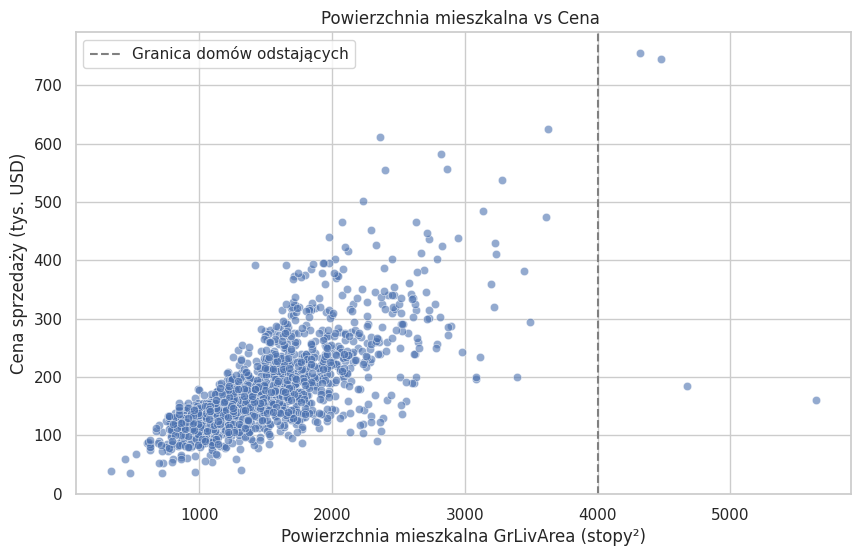

In [11]:
# 2. Wykres punktowy: powierzchnia mieszkalna vs cena.
plt.figure(figsize=(10, 6))
sns.scatterplot(x=df['GrLivArea'], y=df['SalePrice'] / 1000, alpha=0.6)
plt.title('Powierzchnia mieszkalna vs Cena ')
plt.xlabel('Powierzchnia mieszkalna GrLivArea (stopy²)')
plt.ylabel('Cena sprzedaży (tys. USD)')
plt.axvline(4000, color='grey', linestyle='--', label='Granica domów odstających')
plt.legend()
plt.show()

**Odpowiedzi:**  
2.  Zależność między powierzchnią a ceną jest wyraźna i stosunkowo liniowa. Dziwne odstające obserwacje (domy o powierzchni powyżej 4000 stóp    kwadratowych, ale sprzedane poniżej 200 tys. USD) to transakcje częściowe (Partial), które nie odzwierciedlają pełnej ceny rynkowej, a sam autor zbioru zaleca ich usunięcie.  
3. Nie, powierzchnia działki (LotArea) ma znacznie słabszy wpływ na cenę niż powierzchnia mieszkalna domu (GrLivArea). Powierzchnia domu wykazuje, silną i dość liniową zależność (większy dom = wyższa cena). W przypadku działek zależność ta jest dużo bardziej rozmyta, ponieważ największe działki wcale nie muszą być najdroższe.

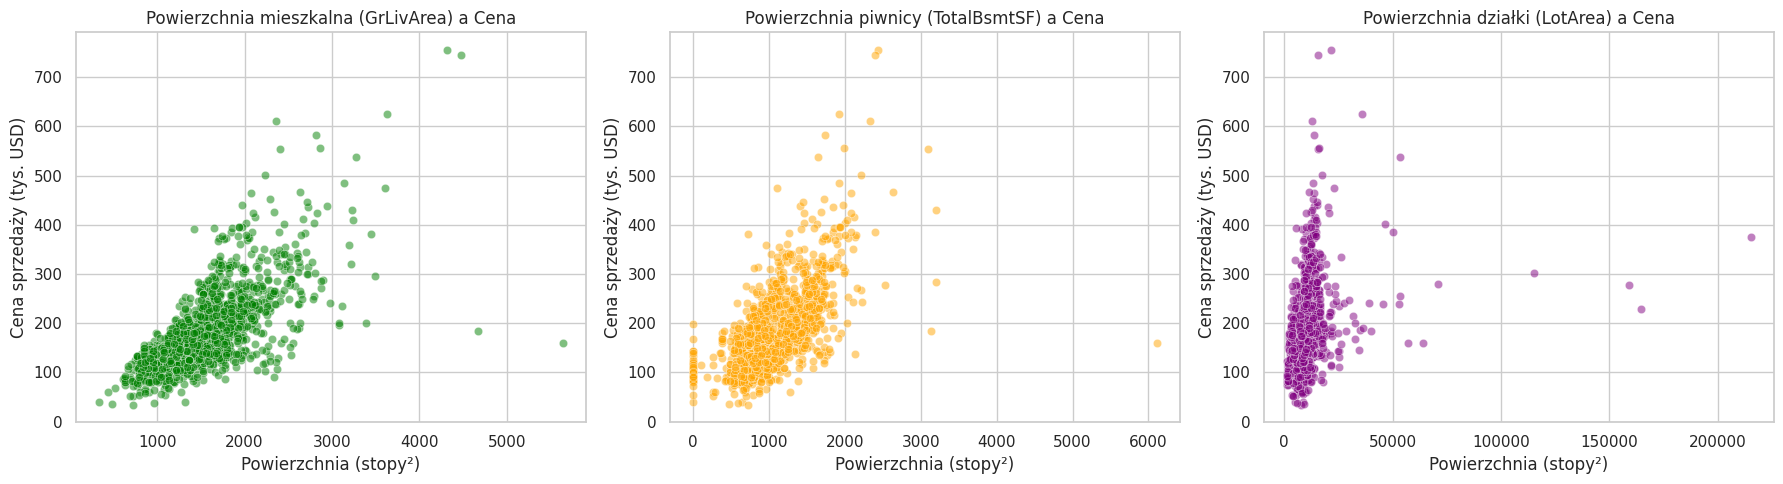

Korelacja poszczególnych powierzchni z ceną:
SalePrice      1.000000
GrLivArea      0.708624
TotalBsmtSF    0.613581
LotArea        0.263843
Name: SalePrice, dtype: float64


In [12]:
# 4. Narysuj wykresy punktowe dla 2–3 rodzajów powierzchni — która ma najsilniejszy związek z ceną?

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# powierzchnia mieszkalna
sns.scatterplot(x='GrLivArea', y=df['SalePrice'] / 1000, data=df, ax=axes[0], alpha=0.5, color='green')
axes[0].set_title('Powierzchnia mieszkalna (GrLivArea) a Cena')
axes[0].set_xlabel('Powierzchnia (stopy²)')
axes[0].set_ylabel('Cena sprzedaży (tys. USD)')

# powierzchnia piwnicy
sns.scatterplot(x='TotalBsmtSF', y=df['SalePrice'] / 1000, data=df, ax=axes[1], alpha=0.5, color='orange')
axes[1].set_title('Powierzchnia piwnicy (TotalBsmtSF) a Cena')
axes[1].set_xlabel('Powierzchnia (stopy²)')
axes[1].set_ylabel('Cena sprzedaży (tys. USD)')

# powierzchnia działki
sns.scatterplot(x='LotArea', y=df['SalePrice'] / 1000, data=df, ax=axes[2], alpha=0.5, color='purple')
axes[2].set_title('Powierzchnia działki (LotArea) a Cena')
axes[2].set_xlabel('Powierzchnia (stopy²)')
axes[2].set_ylabel('Cena sprzedaży (tys. USD)')

plt.tight_layout()
plt.show()

korelacje = df[['SalePrice', 'GrLivArea', 'TotalBsmtSF', 'LotArea']].corr()
print("Korelacja poszczególnych powierzchni z ceną:")
print(korelacje['SalePrice'].sort_values(ascending=False))

**Odpowiedź pkt 4:**  
Najsilniejszy związek z ceną ma powierzchnia mieszkalna (GrLivArea), której współczynnik korelacji z ceną wynosi około 0.71